# PGC low-trap: cooling curve T(t_PGC) + survival

Interactive analysis of `PGCLowTrapScan` runs taken in the **fixed-(f,amp), scan-(t_PGC x release)** mode. Reuses the BLAS-free helpers from `analyze_pgc_time_release.py`:

- **Panel A** - recapture vs release time, one curve per `t_PGC` -> the temperature at each PGC duration (a curve that decays *later* = colder).
- **Panel B** - half-recapture release (temperature proxy, higher = colder) vs `t_PGC` **and** retention@0 vs `t_PGC` -> the cooling **knee** (shortest `t_PGC` reaching the cold floor) and the loss guard (retention@0 falling = atom *lost*, not cold).

Run with the **working-BLAS `python`** kernel; matplotlib crashes in the artiq7_claude env.

In [31]:
import sys, os, glob
from pathlib import Path
_ANALYSIS_DIR = r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis"
if _ANALYSIS_DIR not in sys.path:
    sys.path.insert(0, _ANALYSIS_DIR)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%load_ext autoreload
%autoreload 2
from analyze_pgc_time_release import (
    RESULTS_DIR, KNEE_FRAC, find_run, load_run, tpgc_release_table, wilson, _half_release, _curve,
)
print("Results dir:", RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. List recent runs

In [32]:
files = sorted(glob.glob(str(RESULTS_DIR / "**" / "*-PGCLowTrapScan.h5"), recursive=True),
               key=lambda f: int(os.path.basename(f).split("-")[0]))
if not files:
    print("No *-PGCLowTrapScan.h5 found yet.")
for f in files[-12:]:
    rid = int(os.path.basename(f).split("-")[0])
    d, s, _ = load_run(f)
    n = len(np.atleast_1d(d.get("pgc_t_pgc_us", [])))
    nl = int(np.sum(np.atleast_1d(d.get("pgc_atom_loaded", [0])).astype(int)))
    nt = len(set(np.round(np.atleast_1d(d.get("pgc_t_pgc_us", [0.0])).astype(float), 1)))
    print(f"RID {rid:>5} | {n:>6} pts | {nl:>5} loaded | {nt:>3} t_PGC vals")

RID   581 |      0 pts |  1157 loaded |   1 t_PGC vals
RID   584 |      0 pts |  6605 loaded |   1 t_PGC vals
RID   587 |   1250 pts |  1223 loaded |   5 t_PGC vals


## 2. Select a run

Set `RID` to an int, or `None` for the latest.

In [33]:
RID = None   # <-- int or None (latest)

path = find_run(RID)
data, snap, rid = load_run(path)
table = tpgc_release_table(data)              # filters loaded==1
tpgcs = sorted({t for (t, r) in table})
releases = sorted({r for (t, r) in table})
fvals = sorted({round(float(x), 0) for x in np.asarray(data['pgc_f']).astype(float)})
avals = sorted({round(float(x), 4) for x in np.asarray(data['pgc_amp']).astype(float)})

print("File :", os.path.basename(path))
print(f"RID {rid}  |  f (MHz): {[round(x/1e6, 4) for x in fvals]}   amp: {avals}")
print("t_PGC values (us):", tpgcs)
print("release times (us):", releases)

File : 000000587-PGCLowTrapScan.h5
RID 587  |  f (MHz): [130.0]   amp: [0.28]
t_PGC values (us): [200.0, 400.0, 600.0, 800.0, 1000.0]
release times (us): [0.0, 50.0, 100.0, 150.0, 200.0]


## 3. Panel A - recapture vs release, one curve per t_PGC

t_PGC=    200 us: half-recapture release = 68.2 us
t_PGC=    400 us: half-recapture release = 77.8 us
t_PGC=    600 us: half-recapture release = 84.1 us
t_PGC=    800 us: half-recapture release = 108.9 us
t_PGC=   1000 us: half-recapture release = 114.1 us


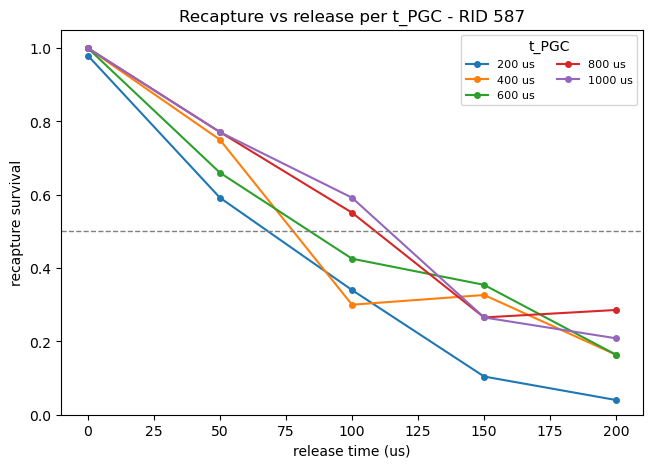

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for t in tpgcs:
    rx, ry = _curve(table, t, releases)
    if len(rx) >= 2:
        ax.plot(rx, ry, "o-", label=f"{t:.0f} us", lw=1.5, ms=4)
        half = _half_release(rx, ry)
        print(f"t_PGC={t:>7.0f} us: half-recapture release = " + (f"{half:.1f} us" if half is not None else "n/a"))
ax.axhline(0.5, ls="--", color="gray", lw=1)
ax.set_xlabel("release time (us)")
ax.set_ylabel("recapture survival")
ax.set_ylim(0, 1.05)
ax.set_title(f"Recapture vs release per t_PGC - RID {rid}")
ax.legend(fontsize=8, ncol=2, title="t_PGC")
plt.show()

## 4. Panel B - cooling knee + survival vs t_PGC

Half-recapture release (higher = colder) rising to a plateau = the **knee**. retention@0 dropping = atom **lost**, not cold.

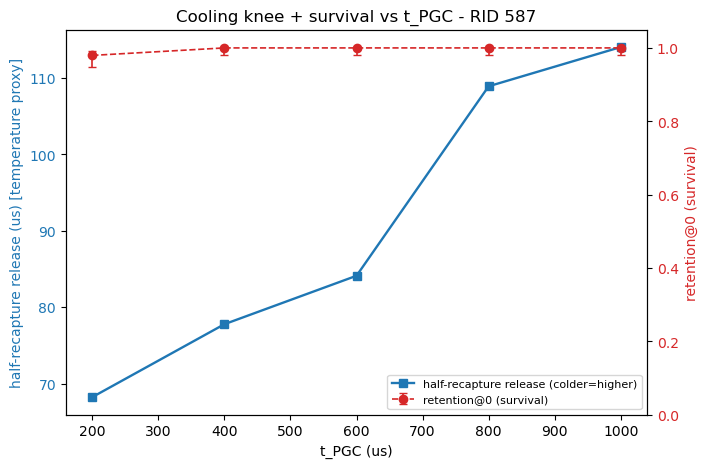

max half-recapture release = 114.1 us; knee (>= 90% of max) at t_PGC = 800.0 us


In [35]:
halves = []
for t in tpgcs:
    rx, ry = _curve(table, t, releases)
    halves.append((t, _half_release(rx, ry) if len(rx) >= 2 else None))

tt = [t for (t, h) in halves if h is not None]
hh = [h for (t, h) in halves if h is not None]
r0t, r0p, r0lo, r0hi = [], [], [], []
for t in tpgcs:
    kn = table.get((t, 0.0))
    if kn and kn[1] > 0:
        p, lo, hi = wilson(kn[0], kn[1])
        r0t.append(t); r0p.append(p); r0lo.append(max(0.0, p-lo)); r0hi.append(max(0.0, hi-p))

fig, axL = plt.subplots(figsize=(7.5, 5))
if tt:
    axL.plot(tt, hh, "s-", color="C0", lw=1.7, ms=6, label="half-recapture release (colder=higher)")
axL.set_xlabel("t_PGC (us)")
axL.set_ylabel("half-recapture release (us) [temperature proxy]", color="C0")
axL.tick_params(axis="y", labelcolor="C0")
axRt = axL.twinx()
if r0t:
    axRt.errorbar(r0t, r0p, yerr=[r0lo, r0hi], fmt="o--", color="C3", capsize=3, lw=1.2, label="retention@0 (survival)")
axRt.set_ylabel("retention@0 (survival)", color="C3")
axRt.set_ylim(0, 1.05)
axRt.tick_params(axis="y", labelcolor="C3")
lns, lbs = axL.get_legend_handles_labels()
l2, lb2 = axRt.get_legend_handles_labels()
axL.legend(lns + l2, lbs + lb2, fontsize=8, loc="lower right")
axL.set_title(f"Cooling knee + survival vs t_PGC - RID {rid}")
plt.show()

if hh:
    hmax = max(hh)
    knee = next((t for (t, h) in zip(tt, hh) if h >= KNEE_FRAC * hmax), None)
    print(f"max half-recapture release = {hmax:.1f} us; knee (>= {KNEE_FRAC:.0%} of max) at t_PGC = {knee} us")

## 5. (optional) one-shot PNG via the script

`analyze(path)` writes a 2-panel PNG next to the `.h5`.

In [36]:
# from analyze_pgc_time_release import analyze
# analyze(path)